## **XG Boost** ##

In [11]:
import pandas as pd 
import numpy as np

from scipy.stats import randint, uniform
from xgboost import XGBRegressor
import xgboost as xgbl
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, accuracy_score

import graphviz
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv("data.csv")
df["From"] = pd.to_datetime(df["From"])
df = df.sort_values("From").reset_index(drop=True)

In [4]:
mete_col = ["Diurnal temperature range (°C)", "Mean temperature (°C)", "Mean humidity (%)", "Solar radiation (MJ/m²)", "Air pressure (hPa)", "Dew point temperature (°C)", "Wind speed (km/h)", "Mean UV"]
# flu_col = ["H1", "H3", "B", "AandB"]
flu_col = ["H1", "H3", "AandB"]

In [5]:
for col in flu_col: 
    tmp_df = df.copy()

    # Seperate case for type AH1 influenza
    if col == "H1":
        for n in range(4):
            tmp_df[f"{col}_Lag{n+1}"] = tmp_df[col].shift(n+1)
        tmp_df[f"{col}_volatility"] = tmp_df[col].shift(1).rolling(window=4).std()
        tmp_df[f"{col}_rolling_mean"] = tmp_df[col].shift(1).rolling(window=4).mean()
    else:
        for n in range(2):
            tmp_df[f"{col}_Lag{n+1}"] = tmp_df[col].shift(n+1)
        tmp_df[f"{col}_volatility"] = tmp_df[col].shift(1).rolling(window=4).std()
        tmp_df[f"{col}_rolling_mean"] = tmp_df[col].shift(1).rolling(window=4).mean()

    tmp_df = tmp_df.dropna().reset_index(drop=True)

    X = tmp_df.drop(columns=["From"]+flu_col)


    print(f"{'='*70} {col} {'='*70}")
    y = tmp_df[col]

    train_end = int(tmp_df.shape[0] * 0.8)
    X_train, X_test = X.iloc[:train_end], X.iloc[train_end:]
    y_train, y_test = y.iloc[:train_end], y.iloc[train_end:]

    y_train_log = np.log1p(y_train)

    grid = {
        "n_estimators": [x for x in range(100, 1000, 100)],
        "learning_rate": uniform(0.01, 0.20),
        "max_depth": [3, 4, 5, 6, 7, 8],
        "subsample": uniform(0.6, 0.4),
        "colsample_bytree": uniform(0.6, 0.4),
        "min_child_weight": randint(10, 30),
        "reg_alpha": uniform(0, 5),
        "reg_lambda": uniform(1, 10)
    }

    tscv = TimeSeriesSplit(n_splits=5)
    xgb = XGBRegressor(random_state=42)
    xgb_cv = RandomizedSearchCV(estimator=xgb, param_distributions=grid, cv=tscv, scoring="roc_auc", n_jobs=-1)

    xgb_cv.fit(X_train, y_train_log)

    print(f"Best Parameters: {xgb_cv.best_params_}")

    print(f"\nFeature importances: ")
    model = xgb_cv.best_estimator_
    importance = pd.Series(model.feature_importances_, index=X.columns)
    print(importance.sort_values(ascending=False))

    model.fit(X_train, y_train_log)
    
    # Evaluation
    y_pred_log = model.predict(X_train)
    y_pred = np.expm1(y_pred_log)
    print(f"\nModel metrics with train data: ")
    print(f"MAE: {mean_absolute_error(y_train, y_pred):.4f}")
    print(f"MSE: {mean_squared_error(y_train, y_pred):.4f}")
    print(f"R2:  {r2_score(y_train, y_pred):.4f}")

    y_pred_log = model.predict(X_test)
    y_pred = np.expm1(y_pred_log)
    print(f"\nModel metrics with test data: ")
    print(f"MAE: {mean_absolute_error(y_test, y_pred):.4f}")
    print(f"MSE: {mean_squared_error(y_test, y_pred):.4f}")
    print(f"R2:  {r2_score(y_test, y_pred):.4f}")



====================================================================== H1 ======================================================================


c:\Users\yanss\anaconda3\Lib\site-packages\sklearn\model_selection\_search.py:1135: UserWarning: One or more of the test scores are non-finite: [nan nan nan nan nan nan nan nan nan nan]
  warnings.warn(


Best Parameters: {'colsample_bytree': np.float64(0.8059466320214443), 'learning_rate': np.float64(0.14460546565361804), 'max_depth': 3, 'min_child_weight': 25, 'n_estimators': 200, 'reg_alpha': np.float64(3.660816280751518), 'reg_lambda': np.float64(10.942609270656945), 'subsample': np.float64(0.8604868396430208)}

Feature importances: 
H1_Lag1                           0.470352
H1_rolling_mean                   0.363694
H1_Lag2                           0.123366
Week                              0.004984
Dew point temperature (°C)        0.003833
H1_Lag3                           0.003463
H1_Lag4                           0.003386
H1_volatility                     0.003229
Mean temperature (°C)             0.002954
B                                 0.002642
Population                        0.002396
Year                              0.001891
Log_population                    0.001837
Mean UV                           0.001760
pandemic_flag                     0.001701
Wind speed (km/h

c:\Users\yanss\anaconda3\Lib\site-packages\sklearn\model_selection\_search.py:1135: UserWarning: One or more of the test scores are non-finite: [nan nan nan nan nan nan nan nan nan nan]
  warnings.warn(


Best Parameters: {'colsample_bytree': np.float64(0.9128333258779244), 'learning_rate': np.float64(0.13131320733082089), 'max_depth': 7, 'min_child_weight': 18, 'n_estimators': 700, 'reg_alpha': np.float64(1.048603359009344), 'reg_lambda': np.float64(7.216762765403205), 'subsample': np.float64(0.6152941981459324)}

Feature importances: 
H3_Lag1                           0.832666
H3_Lag2                           0.030454
H3_rolling_mean                   0.025904
Year                              0.013476
H3_volatility                     0.008734
Air pressure (hPa)                0.008511
Week                              0.008447
Population                        0.007678
Mean temperature (°C)             0.007082
B                                 0.006895
Dew point temperature (°C)        0.006876
Mean humidity (%)                 0.006252
ContainmentHealthIndex_Average    0.006158
Wind speed (km/h)                 0.005744
Diurnal temperature range (°C)    0.005601
Solar radiation (

c:\Users\yanss\anaconda3\Lib\site-packages\sklearn\model_selection\_search.py:1135: UserWarning: One or more of the test scores are non-finite: [nan nan nan nan nan nan nan nan nan nan]
  warnings.warn(


Best Parameters: {'colsample_bytree': np.float64(0.8621954228102651), 'learning_rate': np.float64(0.16470137152312508), 'max_depth': 5, 'min_child_weight': 26, 'n_estimators': 400, 'reg_alpha': np.float64(4.936796334034756), 'reg_lambda': np.float64(1.0183454948038386), 'subsample': np.float64(0.8800407859200081)}

Feature importances: 
AandB_Lag1                        0.741685
Year                              0.116039
AandB_Lag2                        0.070762
AandB_rolling_mean                0.029096
B                                 0.013799
Mean temperature (°C)             0.004033
AandB_volatility                  0.003242
Week                              0.002880
Air pressure (hPa)                0.002309
Dew point temperature (°C)        0.001911
Population                        0.001911
ContainmentHealthIndex_Average    0.001846
Solar radiation (MJ/m²)           0.001839
Diurnal temperature range (°C)    0.001685
school_flag                       0.001539
Log_population  

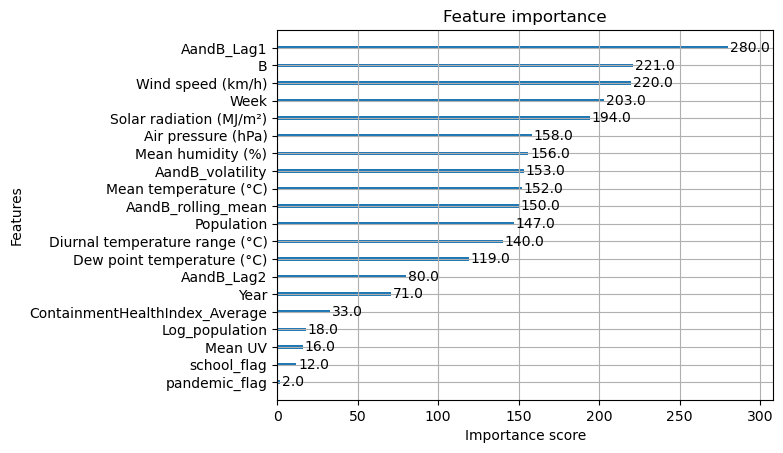

In [12]:
xgbl.plot_importance(model)
plt.show()

XGBoostError: [12:56:57] C:\actions-runner\_work\xgboost\xgboost\src\tree\tree_model.cc:510: Failed to parse graphviz parameters:
	{"graph_attrs": {"num_tree": 2}}
With error:
[12:56:57] C:\actions-runner\_work\xgboost\xgboost\dmlc-core\include\dmlc\./json.h:674: Check failed: ch == '\"' (50 vs. ") : Error at Line 0, around ^`}}`, Expect '"' but get '2'

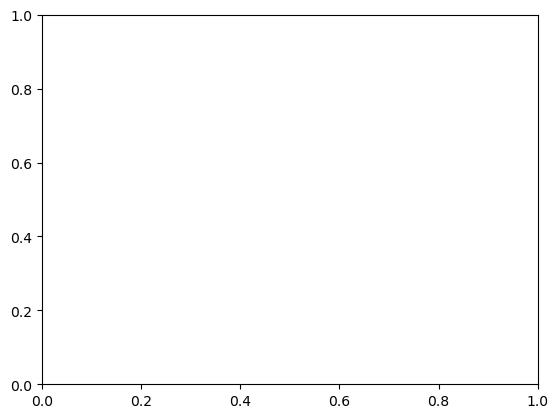

In [14]:
xgbl.plot_tree(model, num_tree=2)